Name: **Sreya S** Roll N0: **B24CSB68** Batch:**R5B**

**LINEAR** **REGRESSION**

In [31]:
#CYCLE 2 LINEAR REGRESSION
#Upload the DB
from google.colab import files
uploaded = files.upload()

Saving LoanPrediction_Cleaned.csv to LoanPrediction_Cleaned (2).csv


In [32]:
# Step 1: Import libraries
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import matplotlib.pyplot as plt

**1. Single Variable Linear Regression**

In [40]:
# Features and target
X = df[['ApplicantIncome']]    # One feature only
y = df['LoanAmount']

In [41]:
#SPLIT THE DATA
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [43]:
#TRAIN THE MODEL
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)
#PREDICT
y_pred = model.predict(X_test)

In [44]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R² Score:", r2_score(y_test, y_pred))

MAE: 32.10862112666223
MSE: 1789.63372626678
RMSE: 42.30406276312927
R² Score: 0.10100390967316619


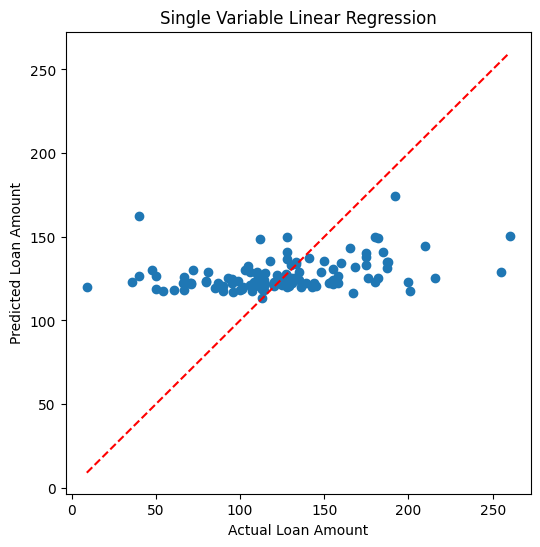

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Loan Amount")
plt.ylabel("Predicted Loan Amount")
plt.title("Single Variable Linear Regression")

plt.show()

**2.Mutli-variable Linear Regression**

In [47]:
df = pd.read_csv('LoanPrediction_Cleaned.csv')
X = df.drop(columns=['Loan_ID', 'LoanAmount', 'Loan_Status'])
y = df['LoanAmount']

In [48]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [49]:
#Train the model
model = LinearRegression()

X_train_processed = X_train.copy()
X_test_processed = X_test.copy()
X_train_processed = pd.get_dummies(X_train_processed, columns=['Property_Area'], drop_first=True)
X_test_processed = pd.get_dummies(X_test_processed, columns=['Property_Area'], drop_first=True)

missing_cols_in_test = set(X_train_processed.columns) - set(X_test_processed.columns)
for c in missing_cols_in_test:
    X_test_processed[c] = 0
# Ensure the order of columns is the same
X_test_processed = X_test_processed[X_train_processed.columns]

model.fit(X_train_processed, y_train)

#Predict
y_pred = model.predict(X_test_processed)

In [50]:
#Evaluate
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R² Score:", r2)


MAE : 32.186988428858776
MSE : 1643.3006669732956
RMSE: 40.53764505954059
R² Score: 0.17451216237291256


In [51]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

comparison.head(10)

,Actual,Predicted
513,110.0,139.281851
70,176.0,123.954718
131,168.0,116.242535
405,128.0,139.086207
544,36.0,121.595516
321,125.0,144.489779
188,128.0,107.078723
29,106.0,129.078558
81,210.0,128.684854
310,71.0,106.032643


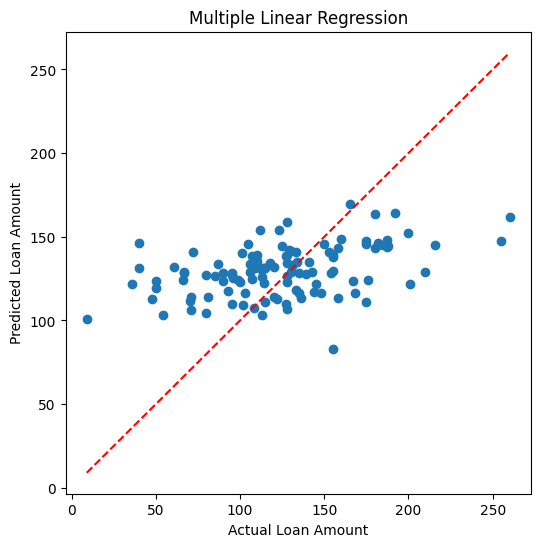

In [52]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Loan Amount")
plt.ylabel("Predicted Loan Amount")
plt.title("Multiple Linear Regression")

plt.show()
plt.show()

In [39]:
coefficients = pd.DataFrame({
    "Feature": X_train_processed.columns, # Use columns from the processed DataFrame
    "Coefficient": model.coef_
})

print(coefficients)

print("Intercept:", model.intercept_)

                    Feature  Coefficient
0                    Gender     3.454698
1                   Married    16.184900
2                Dependents     2.626592
3                 Education   -12.907085
4             Self_Employed     1.489975
5           ApplicantIncome     0.001624
6         CoapplicantIncome     0.000680
7          Loan_Amount_Term     0.080126
8            Credit_History     0.109179
9               Loan_Status    -5.222729
10              TotalIncome     0.002304
11  Property_Area_Semiurban    -8.899402
12      Property_Area_Urban   -11.180524
Intercept: 77.66789125786713
